# T, U y D con `compute_tud`

H₂O de HITRAN2024 (HAPI, todos los isotopólogos) y la US Standard, en 714–1250 cm⁻¹ (8–14 µm).

`compute_tud` da la transmitancia T de la columna, la radiancia ascendente U en el tope y la descendente D en la
superficie. Con ellas, la radiancia en el tope es L = ε·B(T_skin)·T + U + (1 − ε)·T·D.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pylblrtm import compute_tud, from_hapi, planck, us_standard_atmosphere

NU_MIN, NU_MAX = 714.0, 1250.0

sd = from_hapi("H2O", NU_MIN - 25, NU_MAX + 25, iso_id="all")
perfil = us_standard_atmosphere(gases=["H2O"])
print(sd.n_lines, "líneas ·", perfil.n_layers, "capas")

HAPI version: 1.3.0.0
To get the most up-to-date version please check http://hitran.org/hapi
ATTENTION: Python versions of partition sums from TIPS-2021 are now available in HAPI code

           MIT license: Copyright 2021 HITRAN team, see more at http://hitran.org. 

           If you use HAPI in your research or software development,
           please cite it using the following reference:
           R.V. Kochanov, I.E. Gordon, L.S. Rothman, P. Wcislo, C. Hill, J.S. Wilzewski,
           HITRAN Application Programming Interface (HAPI): A comprehensive approach
           to working with spectroscopic data, J. Quant. Spectrosc. Radiat. Transfer 177, 15-30 (2016)
           DOI: 10.1016/j.jqsrt.2016.03.005

           ATTENTION: This is the core version of the HITRAN Application Programming Interface.
                      For more efficient implementation of the absorption coefficient routine, 
                      as well as for new profiles, parameters and other functional,
      

                     Lines parsed: 2262
H2O_iso5_689_1275
                     Lines parsed: 419
H2O_iso6_689_1275
                     Lines parsed: 211
H2O_iso7_689_1275
                     Lines parsed: 2349
Using C:\Users\PC\.pylblrtm\hitran_cache

H2O_iso1_689_1275
                     Lines parsed: 2902
H2O_iso2_689_1275
                     Lines parsed: 847
H2O_iso3_689_1275
                     Lines parsed: 537
H2O_iso4_689_1275
                     Lines parsed: 2262
H2O_iso5_689_1275
                     Lines parsed: 419
H2O_iso6_689_1275
                     Lines parsed: 211
H2O_iso7_689_1275
                     Lines parsed: 2349
Using C:\Users\PC\.pylblrtm\hitran_cache

H2O_iso1_689_1275
                     Lines parsed: 2902
H2O_iso2_689_1275
                     Lines parsed: 847
H2O_iso3_689_1275
                     Lines parsed: 537
H2O_iso4_689_1275
                     Lines parsed: 2262
H2O_iso5_689_1275
                     Lines parsed: 419
H2O_iso6_689_12

9527 líneas · 20 capas


## Entradas

```
compute_tud(spectral_data, profile, nu_min_cm1, nu_max_cm1, *, mu_view=1.0, diffusivity=1.67,
            layer_planck="layer", step_cm1=0.001, line_cutoff_cm1=25.0, tile_width_cm1=2.0,
            voigt="wofz", n_jobs=1, wing_tolerance=None, h2o_continuum=False)
```

Las dos primeras son objetos; las demás, números u opciones.

| entrada | tipo | qué es |
|---|---|---|
| `spectral_data` | `SpectralData` | las líneas de HITRAN y las sumas de partición; aquí sale de `from_hapi` |
| `profile` | `AtmosphericProfile` | la atmósfera por niveles, del tope a la superficie; aquí `us_standard_atmosphere` |
| `nu_min_cm1`, `nu_max_cm1` | float | extremos de la rejilla espectral [cm⁻¹] |
| `mu_view` | float | coseno del ángulo cenital de visión, para T y U (1 = nadir) |
| `diffusivity` | float | secante del camino de D, ≥ 1 |
| `layer_planck` | str | B de cada capa: `"layer"`, `"density"` o `"arithmetic"` (sección 3) |
| `step_cm1` | float | paso de la rejilla [cm⁻¹] |
| `line_cutoff_cm1` | float | cada línea se corta a esta distancia de su centro [cm⁻¹] |
| `tile_width_cm1` | float | ancho de los tramos en que se reparte el cálculo [cm⁻¹]; no cambia el resultado |
| `voigt` | str | forma de línea: `"wofz"` (exacta) o `"humlicek"` (rápida, a 1×10⁻⁴ relativo) |
| `n_jobs` | int | hilos; −1 = todos los núcleos; no cambia el resultado |
| `wing_tolerance` | float o None | sólo con `"humlicek"`: calcula las alas en rejillas más gruesas con ese error relativo |
| `h2o_continuum` | bool | suma el continuo MT_CKD de H₂O |

In [2]:
print(f"profile: {perfil.n_levels} niveles, del tope (índice 0) a la superficie, "
      f"que hacen {perfil.n_layers} capas")
print(f"  pressure_hpa   {str(perfil.pressure_hpa.shape):6s} presión de cada nivel [hPa], creciente")
print(f"  temperature_k  {str(perfil.temperature_k.shape):6s} temperatura de cada nivel [K]")
for gas, x in perfil.vmr.items():
    print(f"  {f'vmr[{gas!r}]':14s} {str(x.shape):6s} razón de mezcla de {gas} en cada nivel [mol/mol]")

profile: 21 niveles, del tope (índice 0) a la superficie, que hacen 20 capas
  pressure_hpa   (21,)  presión de cada nivel [hPa], creciente
  temperature_k  (21,)  temperatura de cada nivel [K]
  vmr['H2O']     (21,)  razón de mezcla de H2O en cada nivel [mol/mol]


In [3]:
plt.rcParams.update({"font.family": "serif", "axes.linewidth": 1.5, "xtick.major.width": 1.2,
                     "ytick.major.width": 1.2, "figure.dpi": 110})


def tb(nu, L):
    """Temperatura de brillo [K] de una radiancia en W/(cm² sr cm⁻¹)."""
    return 1.4387752 * nu / np.log1p(1.191042972e-12 * nu ** 3 / L)


def dbdt(nu, T):
    """dB/dT [W/(cm² sr cm⁻¹ K)], para pasar diferencias de radiancia a kelvin."""
    x = 1.4387752 * nu / T
    return planck(nu, T) * x / T / -np.expm1(-x)


def inversa(x):
    """µm ↔ cm⁻¹ para el eje de arriba."""
    with np.errstate(divide="ignore"):
        return 1e4 / np.asarray(x, float)


def ejes(titulo, ylabel):
    """Longitud de onda abajo, número de onda arriba."""
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.set_xlabel("longitud de onda [µm]")
    ax.set_ylabel(ylabel)
    ax.set_title(titulo)
    arriba = ax.secondary_xaxis("top", functions=(inversa, inversa))
    arriba.set_xlabel("número de onda [cm⁻¹]")
    return fig, ax

## 1. T, U y D

Un `compute_tud` por ángulo de visión, μ = cos θ. T y U dependen de μ; D no, porque la descendente usa la
difusividad.

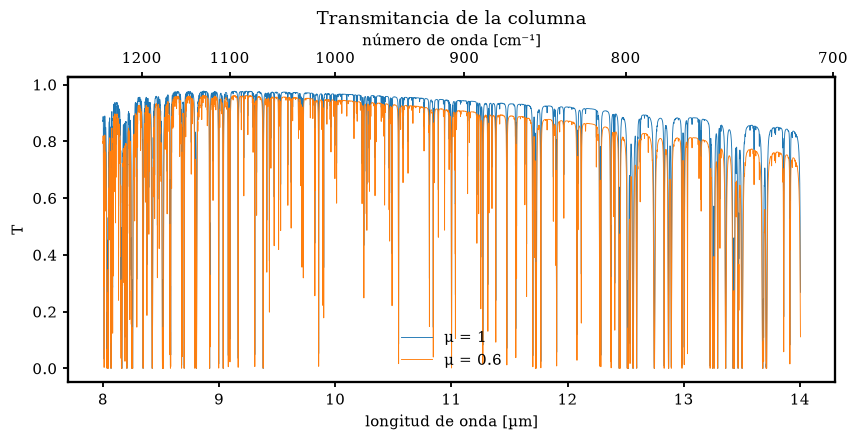

In [4]:
tud = {}
for mu in (1.0, 0.6):
    tud[mu] = compute_tud(
        sd, perfil, NU_MIN, NU_MAX,
        mu_view=mu,             # coseno del ángulo de visión
        diffusivity=1.67,       # factor de difusividad de D (por defecto)
        layer_planck="layer",   # B de cada capa (por defecto; ver sección 3)
        step_cm1=0.01,          # paso de la rejilla [cm⁻¹]
        voigt="humlicek",       # forma de línea rápida ("wofz" es la exacta, más lenta)
        n_jobs=-1,              # todos los núcleos
        h2o_continuum=True,     # suma el continuo de H₂O
    )
nu, T1, U1, D1 = tud[1.0]

fig, ax = ejes("Transmitancia de la columna", "T")
for mu, (_, T, U, D) in tud.items():
    ax.plot(1e4 / nu, T, lw=0.6, label=f"μ = {mu:g}")
ax.legend(frameon=False)
plt.show()

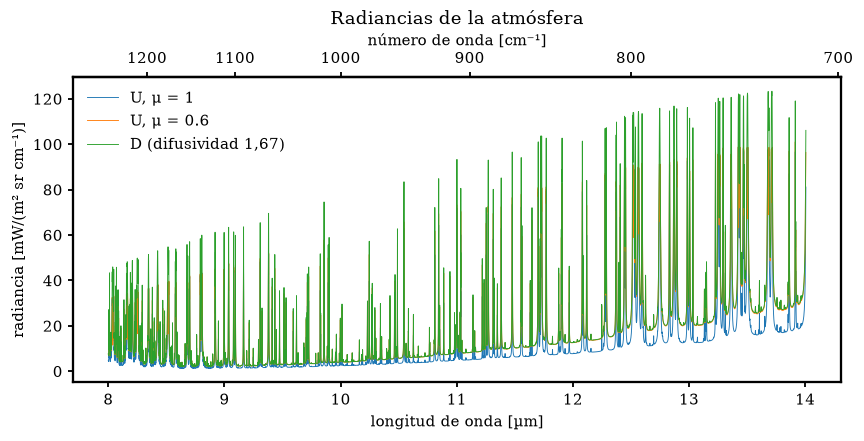

In [5]:
fig, ax = ejes("Radiancias de la atmósfera", "radiancia [mW/(m² sr cm⁻¹)]")
for mu, (_, T, U, D) in tud.items():
    ax.plot(1e4 / nu, U * 1e7, lw=0.6, label=f"U, μ = {mu:g}")
ax.plot(1e4 / nu, D1 * 1e7, lw=0.6, label="D (difusividad 1,67)")
ax.legend(frameon=False)
plt.show()

## 2. Radiancia en el tope

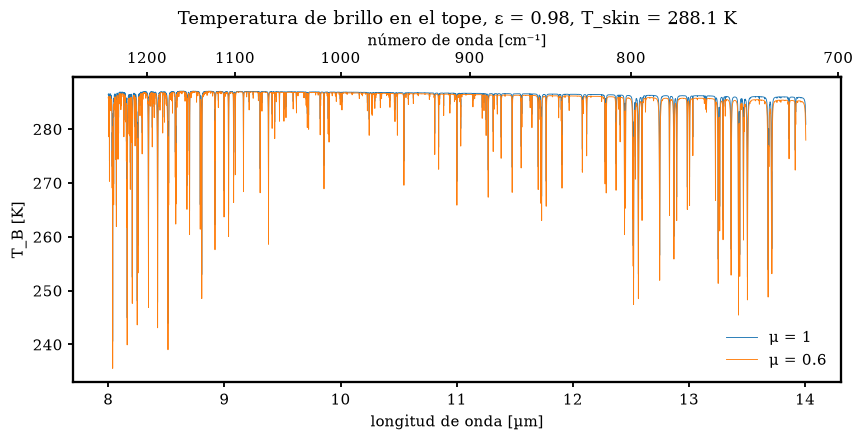

In [6]:
eps, T_skin = 0.98, float(perfil.temperature_k[-1])

fig, ax = ejes(f"Temperatura de brillo en el tope, ε = {eps}, T_skin = {T_skin:.1f} K", "T_B [K]")
for mu, (_, T, U, D) in tud.items():
    L = eps * planck(nu, T_skin) * T + U + (1 - eps) * T * D
    ax.plot(1e4 / nu, tb(nu, L), lw=0.6, label=f"μ = {mu:g}")
ax.legend(frameon=False)
plt.show()

## 3. La B de cada capa

`layer_planck`: `"layer"` (B de la temperatura de la capa, la de las líneas; por defecto), `"density"`
(B de la temperatura ponderada por masa) o `"arithmetic"` (media de B en los dos niveles). Diferencia con
`"layer"`, en kelvin equivalentes a la T de superficie.

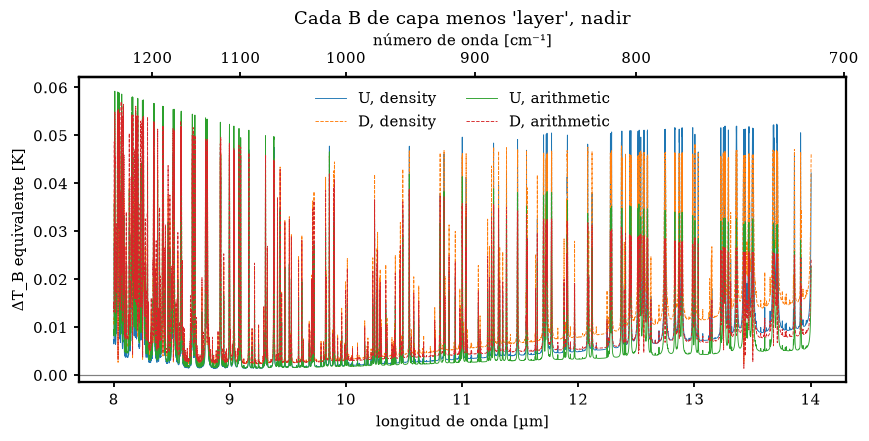

In [7]:
fig, ax = ejes("Cada B de capa menos 'layer', nadir", "ΔT_B equivalente [K]")
for opcion in ("density", "arithmetic"):
    _, _, U, D = compute_tud(sd, perfil, NU_MIN, NU_MAX, layer_planck=opcion,
                             step_cm1=0.01, voigt="humlicek", n_jobs=-1, h2o_continuum=True)
    ax.plot(1e4 / nu, (U - U1) / dbdt(nu, T_skin), lw=0.6, label=f"U, {opcion}")
    ax.plot(1e4 / nu, (D - D1) / dbdt(nu, T_skin), lw=0.6, ls="--", label=f"D, {opcion}")
ax.axhline(0, color="0.5", lw=0.8)
ax.legend(frameon=False, ncol=2)
plt.show()